In [1]:
# PRCP-1005: Forest Cover Prediction
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import warnings

warnings.filterwarnings("ignore")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Libraries imported successfully!")

NumPy: 2.5.4
Pandas: 3.1.1
Scikit-learn: 1.9.1
Libraries imported successfully!


In [2]:
from pathlib import Path

print("Current working directory:")
print(Path.cwd())

print("\nDataset available:")
print(Path("data/train.csv").exists())

print("\nDataset available one level above:")
print(Path("../data/train.csv").exists())

Current working directory:
C:\Rakesh Project\Forest-Cover-Prediction\notebooks

Dataset available:
False

Dataset available one level above:
True


In [3]:
import os
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
os.chdir(PROJECT_ROOT)

print("Project root:", Path.cwd())
print("Dataset found:", Path("data/train.csv").exists())

Project root: C:\Rakesh Project\Forest-Cover-Prediction
Dataset found: True


In [5]:
# Load the Forest Cover dataset

df = pd.read_csv("data/train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (15120, 56)


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


In [6]:
import os

print("Current working directory:", os.getcwd())

Current working directory: C:\Rakesh Project\Forest-Cover-Prediction


In [7]:
df = pd.read_csv("data/train.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (15120, 56)


,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
0,1,2596,51,3,258,0,510,221,232,148,...,0,0,0,0,0,0,0,0,0,5
1,2,2590,56,2,212,-6,390,220,235,151,...,0,0,0,0,0,0,0,0,0,5
2,3,2804,139,9,268,65,3180,234,238,135,...,0,0,0,0,0,0,0,0,0,2
3,4,2785,155,18,242,118,3090,238,238,122,...,0,0,0,0,0,0,0,0,0,2
4,5,2595,45,2,153,-1,391,220,234,150,...,0,0,0,0,0,0,0,0,0,5


In [8]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe().round(2))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15120 entries, 0 to 15119
Data columns (total 56 columns):
 #   Column                              Non-Null Count  Dtype
---  ------                              --------------  -----
 0   Id                                  15120 non-null  int64
 1   Elevation                           15120 non-null  int64
 2   Aspect                              15120 non-null  int64
 3   Slope                               15120 non-null  int64
 4   Horizontal_Distance_To_Hydrology    15120 non-null  int64
 5   Vertical_Distance_To_Hydrology      15120 non-null  int64
 6   Horizontal_Distance_To_Roadways     15120 non-null  int64
 7   Hillshade_9am                       15120 non-null  int64
 8   Hillshade_Noon                      15120 non-null  int64
 9   Hillshade_3pm                       15120 non-null  int64
 10  Horizontal_Distance_To_Fire_Points  15120 non-null  int64
 11  Wilderness_Area1                    15120 non-null  int64

,Id,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,...,Soil_Type32,Soil_Type33,Soil_Type34,Soil_Type35,Soil_Type36,Soil_Type37,Soil_Type38,Soil_Type39,Soil_Type40,Cover_Type
count,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,...,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.00,15120.0
mean,7560.50,2749.32,156.68,16.50,227.20,51.08,1714.02,212.70,218.97,135.09,...,0.05,0.04,0.00,0.01,0.00,0.00,0.05,0.04,0.03,4.0
std,4364.91,417.68,110.09,8.45,210.08,61.24,1325.07,30.56,22.80,45.90,...,0.21,0.20,0.04,0.08,0.03,0.05,0.21,0.20,0.17,2.0
min,1.00,1863.00,0.00,0.00,0.00,-146.00,0.00,0.00,99.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.0
25%,3780.75,2376.00,65.00,10.00,67.00,5.00,764.00,196.00,207.00,106.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,2.0
50%,7560.50,2752.00,126.00,15.00,180.00,32.00,1316.00,220.00,223.00,138.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,4.0
75%,11340.25,3104.00,261.00,22.00,330.00,79.00,2270.00,235.00,235.00,167.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,6.0
max,15120.00,3849.00,360.00,52.00,1343.00,554.00,6890.00,254.00,254.00,248.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,7.0


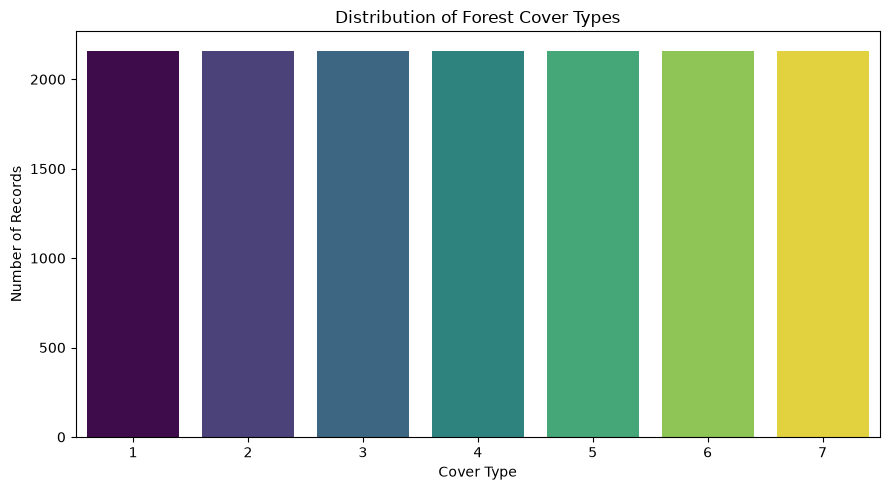

Cover_Type
1    2160
2    2160
3    2160
4    2160
5    2160
6    2160
7    2160
Name: count, dtype: int64


In [34]:
# Forest Cover Type Distribution

import os
os.makedirs("reports/charts", exist_ok=True)

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Cover_Type",
    hue="Cover_Type",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Forest Cover Types")
plt.xlabel("Cover Type")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    "reports/charts/cover_type_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(df["Cover_Type"].value_counts().sort_index())

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset before building machine learning models.

In this section, we examine relationships between environmental features, the distribution of elevation values, and how elevation varies across different forest cover types.

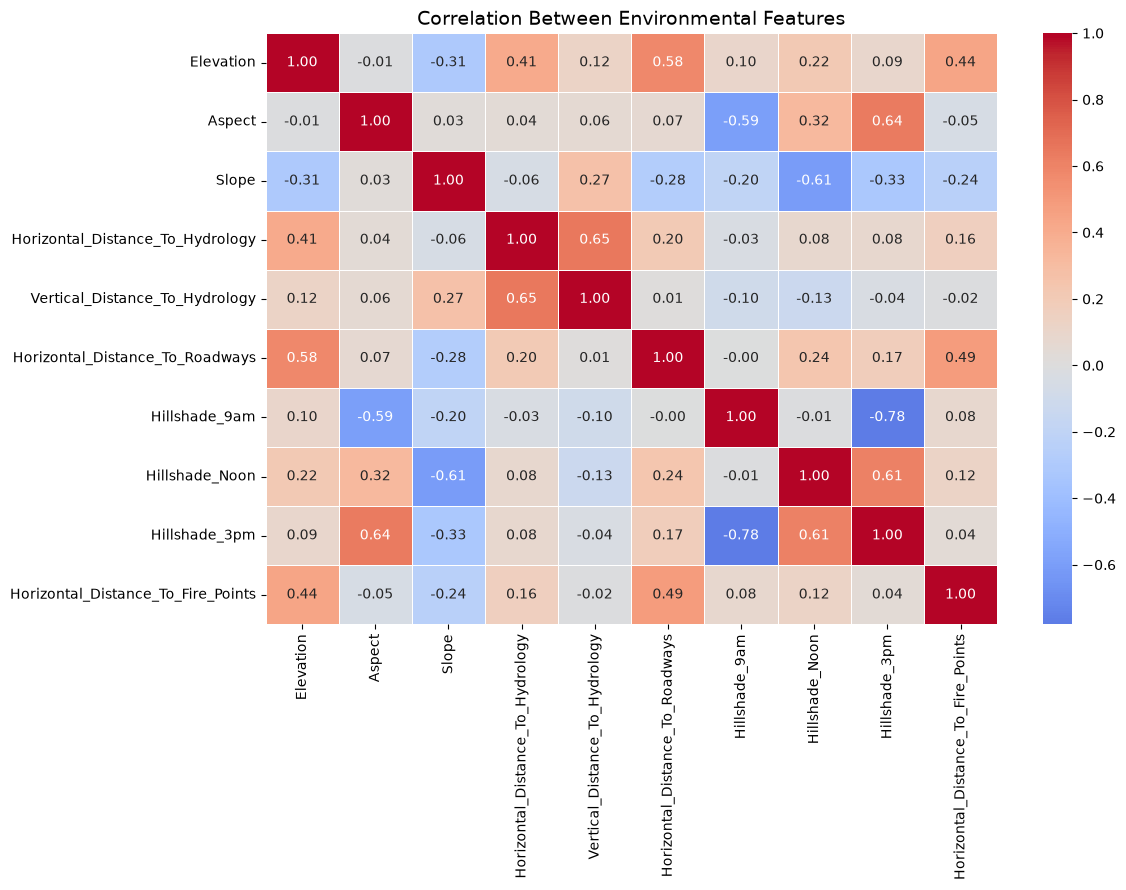

In [35]:
# Feature Correlation Heatmap

environmental_features = [
    "Elevation",
    "Aspect",
    "Slope",
    "Horizontal_Distance_To_Hydrology",
    "Vertical_Distance_To_Hydrology",
    "Horizontal_Distance_To_Roadways",
    "Hillshade_9am",
    "Hillshade_Noon",
    "Hillshade_3pm",
    "Horizontal_Distance_To_Fire_Points"
]

correlation_matrix = df[environmental_features].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Between Environmental Features", fontsize=14)
plt.tight_layout()

plt.savefig(
    "reports/charts/feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

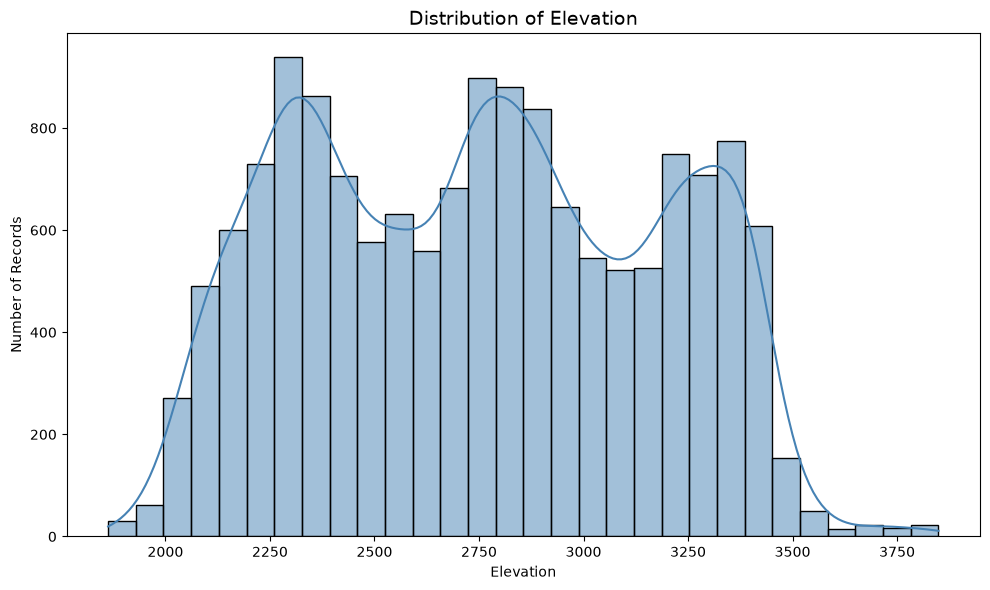

In [36]:
# Elevation Distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Elevation",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Elevation", fontsize=14)
plt.xlabel("Elevation")
plt.ylabel("Number of Records")
plt.tight_layout()

plt.savefig(
    "reports/charts/elevation_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

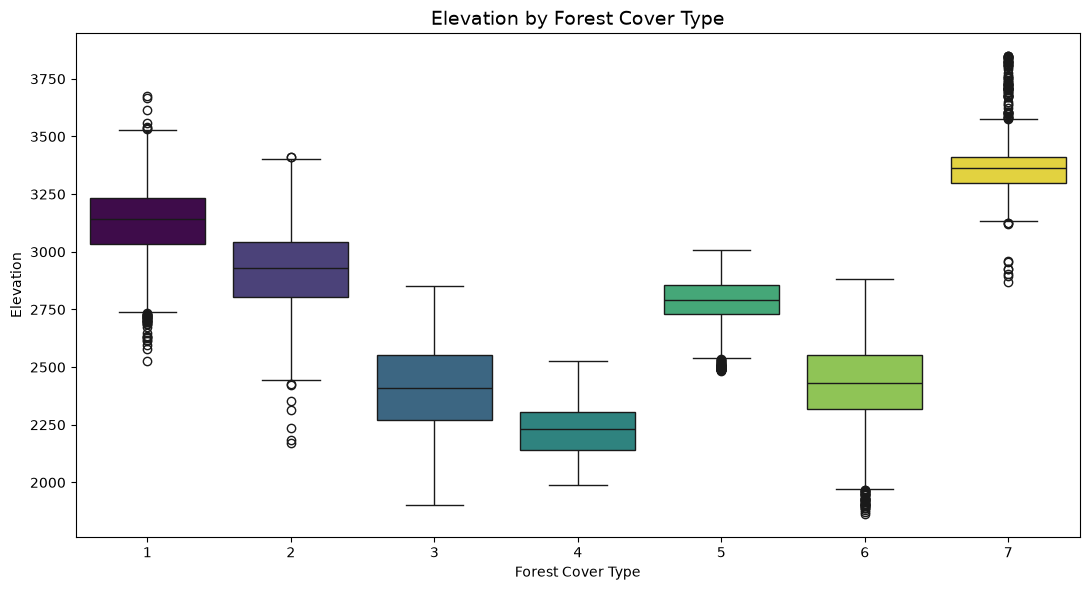

In [37]:
# Elevation by Forest Cover Type

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Cover_Type",
    y="Elevation",
    hue="Cover_Type",
    palette="viridis",
    legend=False
)

plt.title("Elevation by Forest Cover Type", fontsize=14)
plt.xlabel("Forest Cover Type")
plt.ylabel("Elevation")
plt.tight_layout()

plt.savefig(
    "reports/charts/elevation_by_cover_type.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### EDA Observations

- The Forest Cover Type distribution shows the number of records available for each of the seven forest classes.
- The correlation heatmap helps identify relationships between environmental features. Strong correlations may indicate that some features contain related information.
- The elevation histogram shows the distribution and spread of elevation values in the dataset.
- The box plot compares elevation across the seven forest cover types and helps identify differences in their elevation ranges and medians.

These observations help us understand the dataset and identify potentially useful patterns before model training.

In [10]:
# Identify columns with only one unique value

constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print("Constant columns:", constant_columns)

Constant columns: ['Soil_Type7', 'Soil_Type15']


In [11]:
# Check Wilderness Area and Soil Type indicators

wilderness_cols = [col for col in df.columns if col.startswith("Wilderness_Area")]
soil_cols = [col for col in df.columns if col.startswith("Soil_Type")]

print("Wilderness indicator totals:")
print(df[wilderness_cols].sum(axis=1).value_counts().sort_index())

print("\nSoil indicator totals:")
print(df[soil_cols].sum(axis=1).value_counts().sort_index())

Wilderness indicator totals:
1    15120
Name: count, dtype: int64

Soil indicator totals:
1    15120
Name: count, dtype: int64


In [12]:
# Separate features and target

X = df.drop(columns=["Cover_Type", "Id", "Soil_Type7", "Soil_Type15"])
y = df["Cover_Type"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", sorted(y.unique()))

Feature shape: (15120, 52)
Target shape: (15120,)
Target classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (12096, 52)
Testing features: (3024, 52)

Training target distribution:
Cover_Type
1    1728
2    1728
3    1728
4    1728
5    1728
6    1728
7    1728
Name: count, dtype: int64

Testing target distribution:
Cover_Type
1    432
2    432
3    432
4    432
5    432
6    432
7    432
Name: count, dtype: int64


In [14]:
df.loc[X_train.index].to_csv("data/train_split.csv", index=False)
df.loc[X_test.index].to_csv("data/test_split.csv", index=False)

print("Training and testing datasets saved successfully.")

Training and testing datasets saved successfully.


In [15]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)
baseline_accuracy = accuracy_score(y_test, baseline_predictions)

print(f"Baseline Accuracy: {baseline_accuracy:.4f}")
print(f"Baseline Accuracy: {baseline_accuracy * 100:.2f}%")

Baseline Accuracy: 0.1429
Baseline Accuracy: 14.29%


## Model Development and Comparison

In this stage, four machine learning algorithms are trained and evaluated:

1. Decision Tree
2. Random Forest
3. Extra Trees
4. Hist Gradient Boosting

The models are compared using accuracy, macro F1-score and training time to identify a suitable algorithm for predicting forest cover types.

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    "Hist Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
}

results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro"),
        "Training Time (seconds)": round(time.time() - start, 2)
    })

results_df = pd.DataFrame(results).sort_values(by="Accuracy", ascending=False)
display(results_df)

,Model,Accuracy,Macro F1,Training Time (seconds)
2,Extra Trees,0.856481,0.854065,0.63
1,Random Forest,0.854167,0.851812,0.64
3,Hist Gradient Boosting,0.852183,0.849706,6.70
0,Decision Tree,0.791667,0.791170,0.36


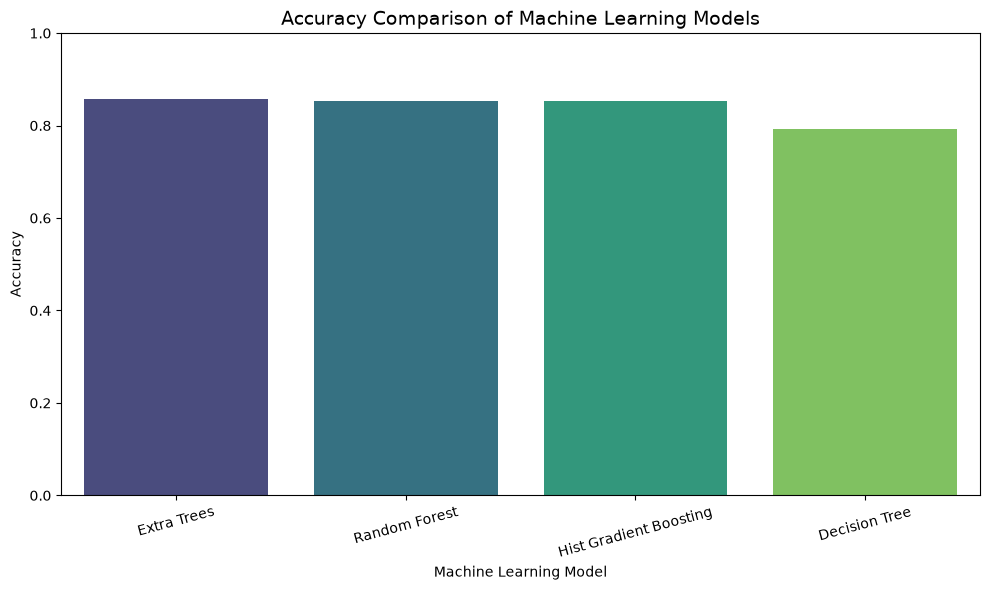

In [38]:
# Model Accuracy Comparison

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Accuracy Comparison of Machine Learning Models", fontsize=14)
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "reports/charts/model_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 20, 30, 40],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    ExtraTreesClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_grid,
    n_iter=12,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation accuracy:")
print(round(random_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 30}

Best cross-validation accuracy:
0.8378


Final Test Accuracy: 0.8485

Classification Report:
              precision    recall  f1-score   support

           1       0.78      0.77      0.77       432
           2       0.77      0.65      0.70       432
           3       0.82      0.79      0.80       432
           4       0.92      0.97      0.94       432
           5       0.88      0.94      0.91       432
           6       0.80      0.86      0.83       432
           7       0.95      0.97      0.96       432

    accuracy                           0.85      3024
   macro avg       0.85      0.85      0.85      3024
weighted avg       0.85      0.85      0.85      3024



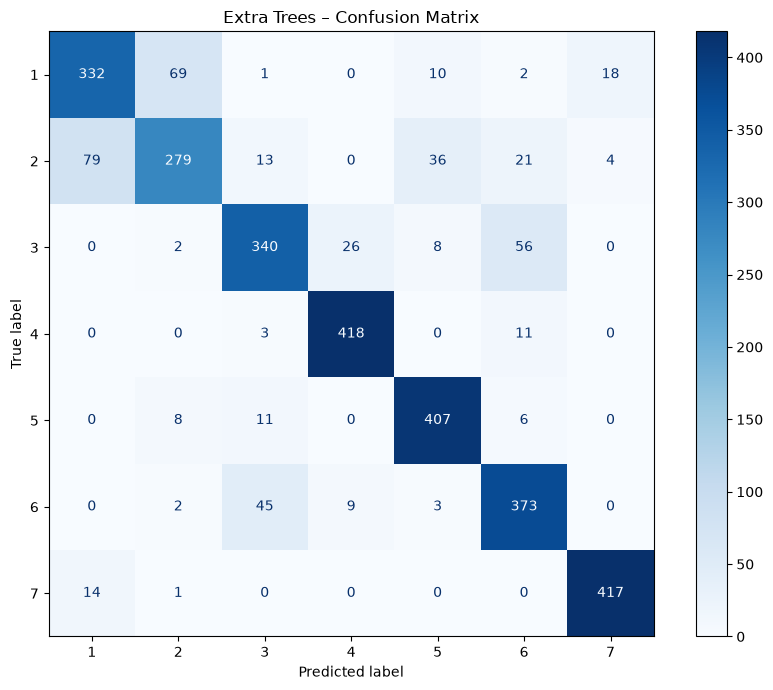

In [18]:
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Final Test Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)

fig, ax = plt.subplots(figsize=(9, 7))
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Extra Trees – Confusion Matrix")
plt.tight_layout()
plt.show()

Top 15 Important Features:


,Feature,Importance
0,Elevation,0.168366
13,Wilderness_Area4,0.070769
5,Horizontal_Distance_To_Roadways,0.070085
9,Horizontal_Distance_To_Fire_Points,0.056968
3,Horizontal_Distance_To_Hydrology,0.051293
1,Aspect,0.041224
6,Hillshade_9am,0.039787
4,Vertical_Distance_To_Hydrology,0.039599
22,Soil_Type10,0.036684
7,Hillshade_Noon,0.035123


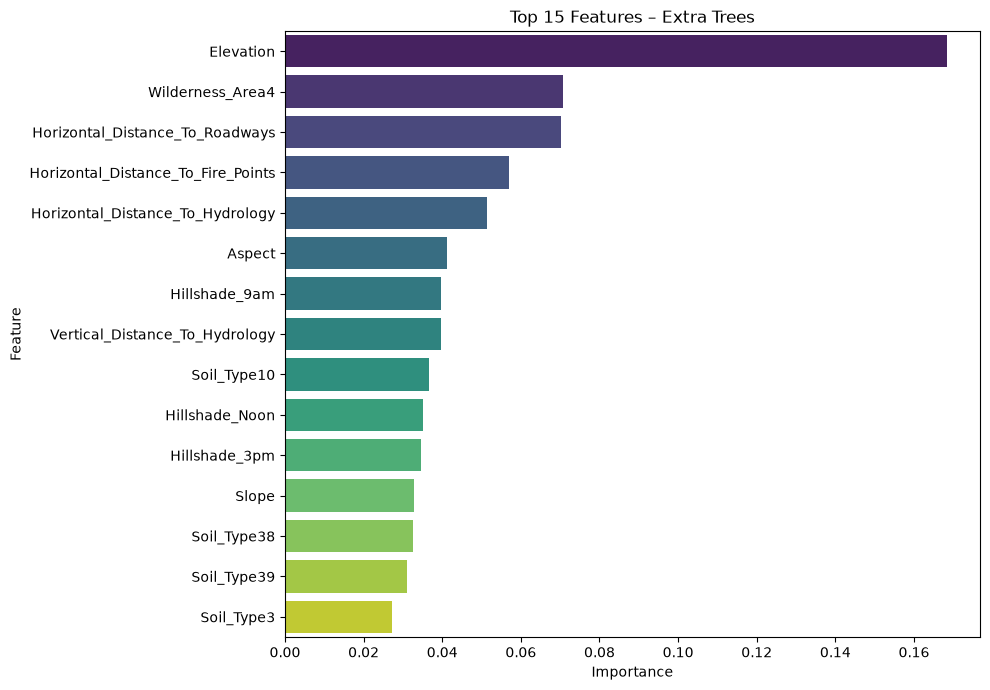

In [19]:
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_model.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Top 15 Important Features:")
display(feature_importance.head(15))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)
plt.title("Top 15 Features – Extra Trees")
plt.tight_layout()
plt.show()

In [20]:
import joblib
import os

os.makedirs("models", exist_ok=True)

model_path = "models/extra_trees_forest_cover.joblib"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: models/extra_trees_forest_cover.joblib


In [21]:
import os
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report

os.makedirs("reports", exist_ok=True)

# Save model accuracy
metrics = pd.DataFrame({
    "Metric": ["Test Accuracy", "Cross-Validation Accuracy"],
    "Score": [accuracy_score(y_test, y_pred), random_search.best_score_]
})
metrics.to_csv("reports/model_metrics.csv", index=False)

# Save classification report
report = classification_report(y_test, y_pred, output_dict=True)
pd.DataFrame(report).transpose().to_csv(
    "reports/classification_report.csv"
)

# Save feature importance
feature_importance.to_csv(
    "reports/feature_importance.csv", index=False
)

print("Evaluation files saved successfully!")
print("Files:")
print("- reports/model_metrics.csv")
print("- reports/classification_report.csv")
print("- reports/feature_importance.csv")

Evaluation files saved successfully!
Files:
- reports/model_metrics.csv
- reports/classification_report.csv
- reports/feature_importance.csv


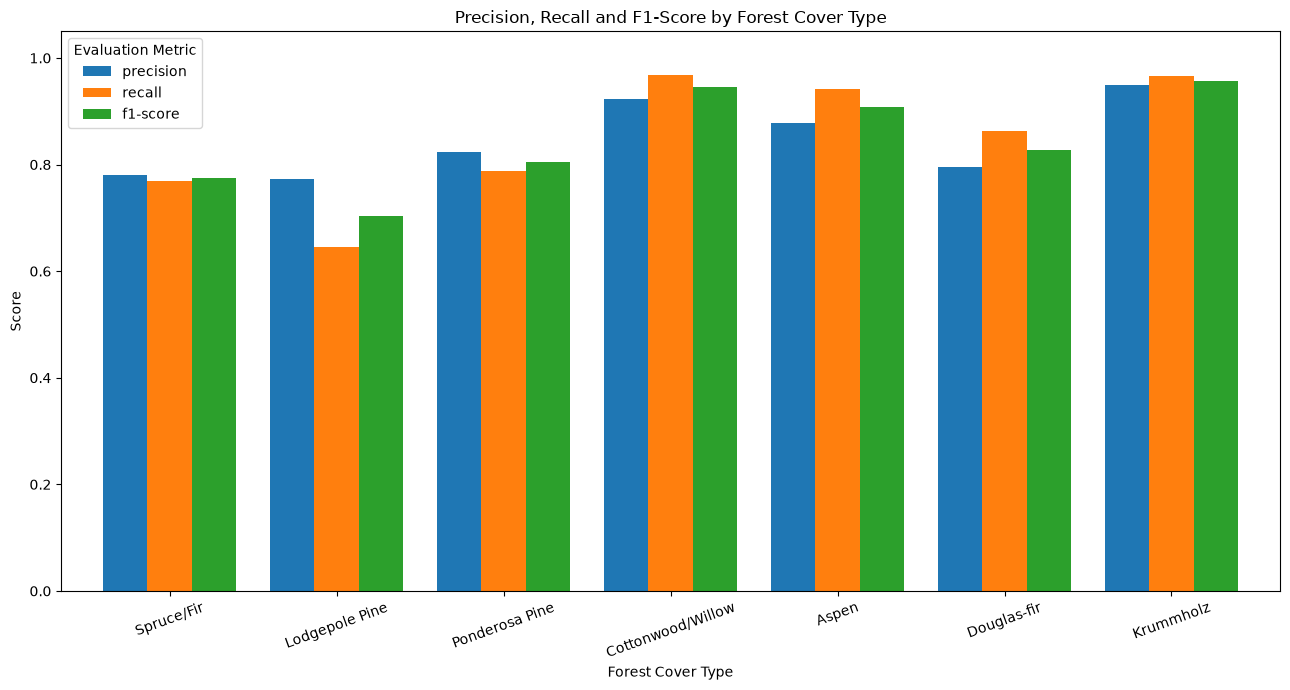

In [39]:
# Precision, Recall and F1-Score Comparison

class_metrics = pd.DataFrame(report).transpose()

class_metrics = class_metrics.loc[
    ["1", "2", "3", "4", "5", "6", "7"],
    ["precision", "recall", "f1-score"]
]

class_metrics.index = [
    "Spruce/Fir",
    "Lodgepole Pine",
    "Ponderosa Pine",
    "Cottonwood/Willow",
    "Aspen",
    "Douglas-fir",
    "Krummholz"
]

ax = class_metrics.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.8
)

plt.title("Precision, Recall and F1-Score by Forest Cover Type")
plt.xlabel("Forest Cover Type")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(title="Evaluation Metric")
plt.tight_layout()

plt.savefig(
    "reports/charts/classification_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Model Comparison and Evaluation Observations

- Four machine learning algorithms were evaluated using accuracy, macro F1-score and training time.
- Extra Trees achieved the highest accuracy among the four models in the initial comparison.
- The final tuned Extra Trees model achieved a test accuracy of approximately 84.85%.
- The classification metrics show that model performance varies across forest cover types.
- Cover Type 2 (Lodgepole Pine) has the lowest F1-score among the seven classes, indicating that it is more difficult for the model to classify correctly.
- Cover Types 4 (Cottonwood/Willow) and 7 (Krummholz) achieved comparatively stronger F1-scores.

These results help identify the strengths and weaknesses of the final model.

In [22]:
results_df.to_csv("reports/model_comparison.csv", index=False)

print("Model comparison saved successfully!")
display(results_df)

Model comparison saved successfully!


,Model,Accuracy,Macro F1,Training Time (seconds)
2,Extra Trees,0.856481,0.854065,0.63
1,Random Forest,0.854167,0.851812,0.64
3,Hist Gradient Boosting,0.852183,0.849706,6.70
0,Decision Tree,0.791667,0.791170,0.36


In [32]:
os.makedirs("reports/charts", exist_ok=True)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title("Confusion Matrix – Extra Trees")
plt.xlabel("Predicted Cover Type")
plt.ylabel("Actual Cover Type")
plt.tight_layout()

plt.savefig(
    "reports/charts/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved successfully!")

Confusion matrix saved successfully.


In [33]:
# Save Feature Importance Chart for the Final Report

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False
)

plt.title("Top 15 Important Features - Extra Trees")
plt.tight_layout()

plt.savefig(
    "reports/charts/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Feature importance chart saved successfully.")

Feature importance chart saved successfully.


In [25]:
import os

for folder in ["data", "models", "notebooks", "reports", "reports/charts"]:
    print(f"\n{folder}/")
    if os.path.exists(folder):
        for item in sorted(os.listdir(folder)):
            print("  ", item)
    else:
        print("  Folder not found")


data/
   test_split.csv
   train.csv
   train_split.csv

models/
   extra_trees_forest_cover.joblib

notebooks/
   .ipynb_checkpoints
   PRCP_1005_Forest_Cover_Prediction.ipynb

reports/
   charts
   classification_report.csv
   feature_importance.csv
   model_comparison.csv
   model_metrics.csv

reports/charts/
   confusion_matrix.png
   feature_importance.png


In [26]:
import os

print("Notebook files in project root:")

for item in os.listdir("."):
    if item.endswith(".ipynb"):
        print(item)

print("\nNotebook files in notebooks folder:")

for item in os.listdir("notebooks"):
    if item.endswith(".ipynb"):
        print(item)

Notebook files in project root:

Notebook files in notebooks folder:
PRCP_1005_Forest_Cover_Prediction.ipynb
